# Solve Inverse Problems - Simulations

Let's try out the inverse module on some simulations.


## 🧪 - Experiment setup
- `fwd`: Forward solution
- `ave`: Measurements
- `ncov`: Noise covariance
- `eig`: Eigenvectors and eigenvalues of the Connectome Lacplacian.
- `gt`: Ground truth

In [1]:
# imports
import mindmap as mm
import mne

# readers
dm = mm.io.TutoManager("../../config.yml")
sub = "simf10"
sub_sim = "simf10-highsnr"
run = "254"

# data
fwd = dm.load(sub, "fwd", desc="inv")
ave = dm.load(sub_sim, "ave", run=run)
ncov = dm.load(sub_sim, "cov", run=run)
eig = dm.load(sub, "eig")
gold = dm.load(sub_sim, "gold", desc="noisy", run=run)
gold_clean = dm.load(sub_sim, "gold", run=run)

# crop
tmin = -0.05
tmax = 0.15

In [2]:
mm.viz.plot_brain_activity(fwd["src"], gold_clean, func_params={"absolute":True}).show()

Widget(value='<iframe src="http://localhost:34881/index.html?ui=P_0x75ba742c7f10_0&reconnect=auto" class="pyvi…

## 🧬 - Data Processing
Estimate regularization parameter

In [3]:
snr, snr_db = mm.analysis.eeg.estimate_evoked_snr(evoked=ave, baseline=(-0.4, -0.2), noise_cov=ncov)
lambda2 = 1.0 / (snr.max()**2)

print(f"Estimated SNR: {snr.max():.3f}")
print(f"Estimated lambda2: {lambda2:.3f}")

# cap the regularization parameter. Smaller values don't regularize anymore.
lambda2 = max(0.01, lambda2)

    Created an SSP operator (subspace dimension = 1)
Computing rank from covariance with rank=None
    Using tolerance 7.1e-12 (2.2e-16 eps * 203 dim * 1.6e+02  max singular value)
    Estimated rank (eeg): 202
    EEG: rank 202 computed from 203 data channels with 1 projector
    Setting small EEG eigenvalues to zero (without PCA)
    Created the whitener using a noise covariance matrix with rank 202 (1 small eigenvalues omitted)
Estimated SNR: 59.249
Estimated lambda2: 0.000


Apply inverse solver

In [4]:
# crop
data = ave.copy().crop(tmin=tmin, tmax=tmax)
ground = gold.copy().crop(tmin=tmin, tmax=tmax)

#ncov = mne.cov.make_ad_hoc_cov(ave.info)
#lambda2 = 0.01

# --------------------------------
# Methods implemented in MindMap
# ¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨
# --------------------------------

# # mindmap's CSET
# inv = mm.analysis.inverse.CSET(
#     forward = fwd,
#     noise_cov = ncov,
#     depth = 0.8,
#     eigenvectors = eig["vec"],
# )

# cset = inv.solve(data, lambda2 = 0.1)


# mindmap's wCSET
inv = mm.analysis.inverse.wCSET(
    forward = fwd,
    noise_cov = ncov,
    depth = 0.2,
    eigenvectors = eig["vec"],
    eigenvalues = eig["val"],
    harm = 5,
    harmonic_method="lowpass"
)

wcset = inv.solve(data, lambda2)

# mindmap's wCSET (log-form spectral prior, GBF paper -- Wang et al. 2026,
# Nat Biomed Eng). Paper-faithful: no depth weighting (their MAP derivation
# has no depth term at all), and `harm` is left at its default because it
# has no effect for harmonic_method="logpass" -- see
# compute_harmonic_prior's docstring in mindmap/analysis/functional/inverse/utils.py
# for why (beta is exactly cancelled by wCSET's own trace-renormalization).
# `cutoff` has no default for "logpass" (raises ValueError if omitted) and
# must always be given explicitly -- 300 is the paper's S (Eq. 2).
inv_logpass = mm.analysis.inverse.wCSET(
    forward = fwd,
    noise_cov = ncov,
    depth = 0,
    eigenvectors = eig["vec"],
    eigenvalues = eig["val"],
    harmonic_method = "logpass",
    cutoff = 150,
)

wcset_logpass = inv_logpass.solve(data, lambda2)

# # mindmap's MCE
# inv = mm.analysis.inverse.MCE(
#     forward = fwd,
#     noise_cov = ncov,
#     depth = 0.8,
# )

# mce = inv.solve(data, lambda2 = 0.1)


# -----------------------------------
# Methods implemented in MNE-Python
# ¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨
# -----------------------------------


inv_mne = mne.minimum_norm.make_inverse_operator(
    info = data.info,
    forward = fwd,
    noise_cov = ncov,
    fixed = True,
    depth = None,
)

# MNE-python's sLORETA
sloreta = mne.minimum_norm.apply_inverse(
    data,
    inv_mne,
    lambda2,
    method = "sLORETA",
)

# MNE-python's dSPM
dspm = mne.minimum_norm.apply_inverse(
    data,
    inv_mne,
    lambda2,
    method = "dSPM",
)

Computing inverse operator with 203 channels.
    203 out of 203 channels remain after picking
Selected 203 channels
    Average patch normals will be employed in the rotation to the local surface coordinates....
    Converting to surface-based source orientations...
    [done]
Whitening the forward solution.
    Created an SSP operator (subspace dimension = 1)
Computing rank from covariance with rank=None
    Using tolerance 7.1e-12 (2.2e-16 eps * 203 dim * 1.6e+02  max singular value)
    Estimated rank (eeg): 202
    EEG: rank 202 computed from 203 data channels with 1 projector
    Setting small EEG eigenvalues to zero (without PCA)
Creating the source covariance matrix
Adjusting source covariance matrix.
Computing SVD of whitened and weighted lead field matrix.
    largest singular value = 2.35201
    scaling factor to adjust the trace = 2.69968e+19 (nchan = 203 nzero = 1)
Preparing the inverse operator for use...
    Scaled noise and source covariance from nave = 1 to nave = 20
 

Evaluate reconstructions

In [6]:
# instanciate variables
metrics = mm.metric.MetricSuite(f"Example {sub}")
times = ground.times
recons = {
    #"cset": cset,
    "wcset": wcset,
    #"wcset_logpass": wcset_logpass,
    "sloreta": sloreta,
    #"dspm": dspm,
    #"mce": mce,
}

# ------------------------------------------------------------
# True source location (ground truth seed, before propagation)
# -- resolved once per run and reused across every solver below,
# same reuse pattern as resection_vertex_mask/adjacency in
# inverse-spike.ipynb. Unlike `ground` (the propagated field used
# for correlation/PR above), this is the actual seed region the
# spike was generated at, recovered from the simulation's own
# saved metadata rather than by thresholding the diffused activity.
# ------------------------------------------------------------
from mindmap.analysis.functional.common.metric import find_peak_localization_error
from mindmap.analysis.simulation.engine import Simulator

src_seed = dm.load(sub, "source", run=run)
simulator, _, _ = Simulator.load(dm.roots["sim"]/f"sub-{sub}"/"simulator")
true_source_mask = src_seed.select_targets(simulator.hm.src, simulator.hm.parc, simulator.hm.ras2tkras)
dipole_positions = mm.anatomy.source_space.get_dipole_positions(fwd["src"]) * 1000

# ------------------------------
# Compute bunch of metrics and
# add them to the Suite.
# ------------------------------

for name, sol in recons.items():
    # correlation
    corr = mm.analysis.inverse.compute_stc_correlation(ground, sol, mode="spatial", method="pearson")
    metrics.register("correlation", corr, Label=name, times=times)

    # cosine
    cosine = mm.analysis.inverse.compute_stc_cosine(ground, sol, mode="spatial", absolute=False)
    metrics.register("cosine", cosine, Label=name, times=times)

    # precision-recall curve at half rising phase
    hrp = mm.analysis.eeg.get_rising_phase(data, ratio=0.25, as_idx=True)    # half rising phase
    activity_mask = ground.data[:,hrp] > 0
    estimated = sol.data[:,hrp]
    pr_curve = mm.core.calc_pr_curve(activity_mask, estimated)
    precision, recall = pr_curve["precision"], pr_curve["recall"]
    metrics.register("precision_hrp", precision, Label=name, recall=recall)

    # precision-recall curve at peak phase
    pp  = mm.analysis.eeg.get_rising_phase(data, ratio=1, as_idx=True)      # peak phase
    activity_mask = ground.data[:,pp] > 0
    estimated = sol.data[:,pp]
    #pr_curve = mm.core.calc_pr_curve(acivity_mask, estimated)
    #precision, recall = pr_curve["precision"], pr_curve["recall"]
    #metrics.register("precision_pp", precision, Label=name, recall=recall)

    # localization error: distance from this solver's single loudest vertex
    # to the true seed region -- 0 if it lands inside it. Classic baseline,
    # blind to multifocal maps, so read alongside the PR curve above rather
    # than alone.
    hit_hrp = find_peak_localization_error(sol.data[:, hrp], true_source_mask, dipole_positions)
    hit_pp = find_peak_localization_error(sol.data[:, pp], true_source_mask, dipole_positions)
    metrics.register("localization_error_hrp", hit_hrp["distance_mm"], Label=name)
    metrics.register("localization_error_pp", hit_pp["distance_mm"], Label=name)

    print(f"{name}: localization error (hrp) = {hit_hrp['distance_mm']:.1f} mm"
          f"   localization error (pp) = {hit_pp['distance_mm']:.1f} mm")
    print(f"{name}: correlation (hrp) = {corr[hrp].item():.3f}"
          f"   correlation (pp) = {corr[pp].item():.3f}")

wcset: localization error (hrp) = 3.7 mm   localization error (pp) = 3.7 mm
wcset: correlation (hrp) = 0.188   correlation (pp) = 0.796
sloreta: localization error (hrp) = 3.8 mm   localization error (pp) = 7.5 mm
sloreta: correlation (hrp) = 0.131   correlation (pp) = 0.184


## 📊 - Visualization

Measurements - timeseries

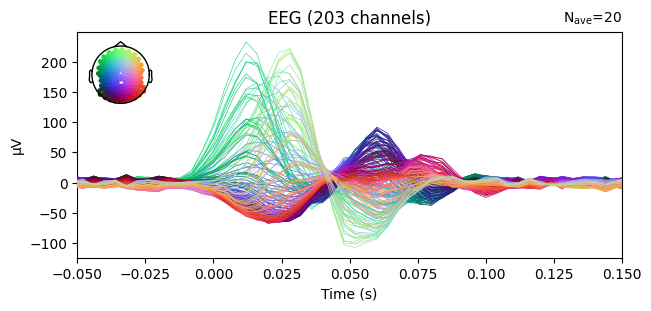

In [7]:
_ = ave.plot(xlim=(tmin, tmax))



Measurements - topographies

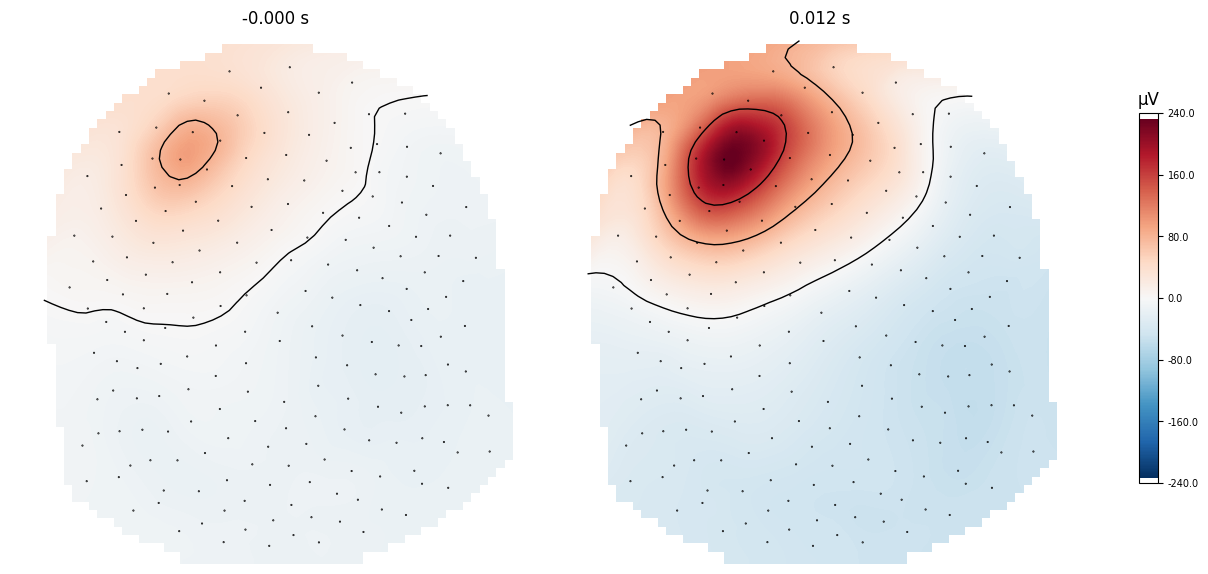

In [8]:
hrp = mm.analysis.eeg.get_rising_phase(ave, ratio=0.25)    # half rising phase
pp  = mm.analysis.eeg.get_rising_phase(ave, ratio=1)      # peak phase

_ = ave.plot_topomap(times=[hrp, pp], size=4, extrapolate="local", outlines=None)

Source reconstruction

In [9]:
tmin, tmax = -0.025, 0.1
mm.viz.plot_brain_activity(
    source_space = fwd["src"],
    functionals = [wcset.copy().crop(tmin, tmax), sloreta.copy().crop(tmin, tmax), ground.copy().crop(tmin, tmax)],
    title = ["wcset", "sloreta",  "gold"],
    func_params = {"normalize": "max", "absolute": True}
).show()

/home/nino/Code/mindmap/mindmap/viz/vista.py:85: UserWarning: Inconsistent time vectors detected across meshes. Using the first available.
  warnings.warn("Inconsistent time vectors detected across meshes. Using the first available.")


Widget(value='<iframe src="http://localhost:34881/index.html?ui=P_0x75ba2e65da10_1&reconnect=auto" class="pyvi…

In [146]:
mm.viz.plot_brain_activity(fwd["src"], ground, func_params={"normalize":"max", "absolute": True}).show()

Widget(value='<iframe src="http://localhost:38881/index.html?ui=P_0x7979297b4c10_37&reconnect=auto" class="pyv…

In [159]:
mm.viz.plot_spectrum(eig["vec"].T @ wcset.data, times = wcset.times).show()
# logpass's hard cutoff (cutoff=300 above) should show up here as ~exactly
# zero energy past mode 300.
mm.viz.plot_spectrum(eig["vec"].T @ wcset_logpass.data, times = wcset_logpass.times).show()

Measured metrics.

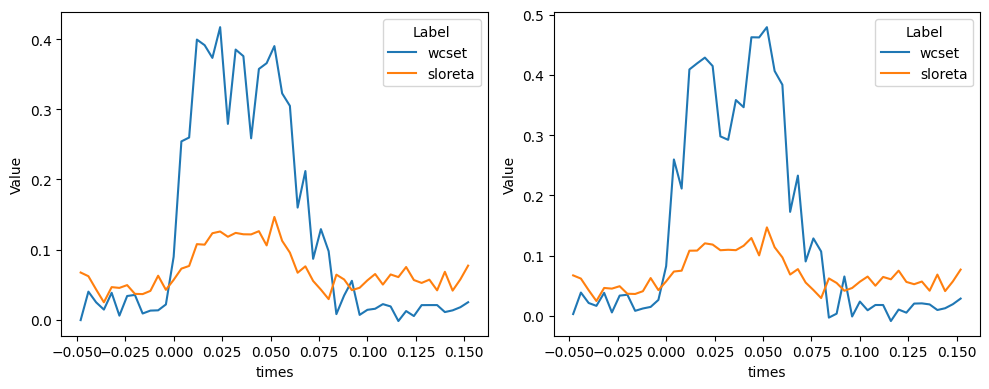

In [175]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
metrics.plot.line(metric="correlation", x="times", group_by="Label", filters={"Label": ["cset", "sloreta", "wcset", "wcset_logpass", "dspm"]}, ax=axes[0])
metrics.plot.line(metric="cosine", x="times", group_by="Label", filters={"Label": ["cset", "sloreta", "wcset", "wcset_logpass", "dspm"]}, ax=axes[1])
fig.tight_layout()

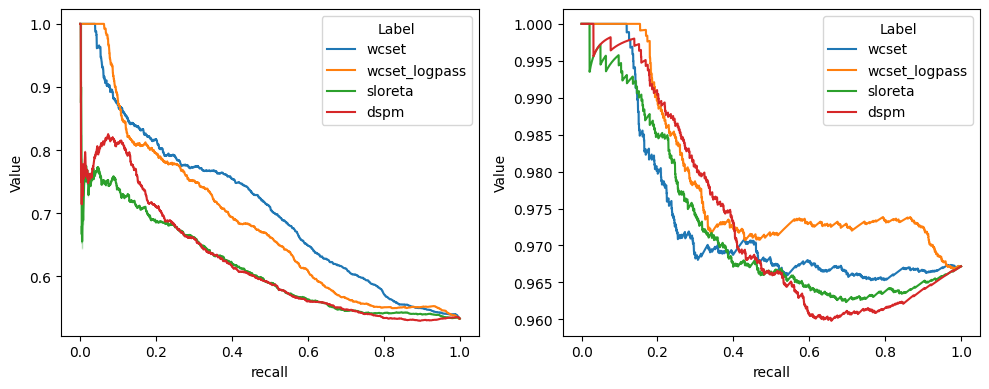

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
metrics.plot.line(metric="precision_hrp", x="recall", group_by="Label", filters={"Label": ["sloreta", "wcset", "wcset_logpass", "dspm"]}, ax=axes[0])
metrics.plot.line(metric="precision_pp", x="recall", group_by="Label", filters={"Label": ["sloreta", "wcset", "wcset_logpass", "dspm"]}, ax=axes[1])
fig.tight_layout()

In [ ]:
import mindmap as mm
from pathlib import Path


# 1. Define paths and methods
dm = mm.io.TutoManager("../../config.yml")
sub = "simf10"
AVE_DIR = dm.roots["mm"]/f"sub-{sub}"/"ave"
methods = ["dspm", "sloreta", "cset", "wcset"]
lambda2 = {"dspm": 0.01, "sloreta": 0.01, "cset": 0.1, "wcset": 0.1}
crop = (-0.01, 0.15)

# 2. Gather all files
all_files = [f for f in AVE_DIR.glob("*.fif") if "template" not in f.name]
total_dataset_size = len(all_files)

# 3. Filter out what is already done
print("Checking disk for existing results...")
files_ave = mm.analysis.inverse.filter_remaining_files(all_files, methods)

already_done = total_dataset_size - len(files_ave)
print(f"Dataset Status: {already_done}/{total_dataset_size} files already completed.")
print(f"Files left to process: {len(files_ave)}")

# Generate matching covariance file paths
files_cov = [Path(str(f).replace("ave", "cov")) for f in files_ave]

for fcov in files_cov:
    if not fcov.exists():
        raise FileNotFoundError(f"Missing expected covariance file: {fcov}")

# 4. Load static variables
forward = dm.load(sub, "fwd", desc="inv")
eig = dm.load(sub, "eig")

# 5. Build one InverseTask per remaining file -- foutputs precomputed here
# (via resolve_solution_paths) since dm can't cross into a worker process.
tasks = [
    mm.analysis.inverse.InverseTask(
        fave=fave,
        fcov=fcov,
        foutputs=mm.analysis.inverse.resolve_solution_paths(fave, methods),
    )
    for fave, fcov in zip(files_ave, files_cov)
]

In [ ]:
mne_methods = {"sloreta": "sLORETA", "dspm": "dSPM", "mne": "MNE"}


def preprocess_crop(ctx):
    return {"ave": ctx["ave"].copy().crop(tmin=crop[0], tmax=crop[1])}


def reconstruct(ctx):
    ave, ncov = ctx["ave"], ctx["ncov"]
    solutions = {}

    inv_mne = None
    if any(m in methods for m in mne_methods):
        inv_mne = mne.minimum_norm.make_inverse_operator(
            info=ave.info, forward=forward, noise_cov=ncov,
            fixed=True, depth=None, verbose="warning",
        )

    for m in methods:
        if m == "cset":
            inv = mm.analysis.inverse.CSET(
                forward=forward, noise_cov=ncov, depth=0.8, eigenvectors=eig["vec"],
            )
            solutions[m] = inv.solve(ave, lambda2=lambda2[m])

        elif m == "wcset":
            inv = mm.analysis.inverse.wCSET(
                forward=forward, noise_cov=ncov, depth=0.8,
                eigenvectors=eig["vec"], eigenvalues=eig["val"], harm=0.8,
            )
            solutions[m] = inv.solve(ave, lambda2[m])

        elif m == "mce":
            inv = mm.analysis.inverse.MCE(forward=forward, noise_cov=ncov, depth=0.8)
            solutions[m] = inv.solve(ave, lambda2=lambda2[m])

        elif m in mne_methods:
            solutions[m] = mne.minimum_norm.apply_inverse(
                ave, inv_mne, lambda2[m], method=mne_methods[m], verbose="warning",
            )

    return {"solutions": solutions}


def save_solutions(ctx):
    task, solutions = ctx["task"], ctx["solutions"]
    for method, sol in solutions.items():
        sol.save(task.foutputs[method], overwrite=True, verbose="warning")
    return f"Finished processing: {Path(task.fave).name}"

In [ ]:
print("Spawning parallel workers across available cores...")

results = mm.tasks.run_parallel_pipeline(
    tasks, preprocess_fn=preprocess_crop, process_fn=reconstruct, postprocess_fn=save_solutions, n_jobs=-1,
)

print("\nProcessing cycle complete!")